# CompFlow demo: from two frames to a dense motion map

This notebook illustrates how the public **CompFlow** repository (https://github.com/migueldiaz1/CompFlow) works, end to end, on a `SynthCells` sample pair:

1. load a frame pair from the repo's bundled sample data,
2. look at it -- full cell, then three 30x30 zoomed regions,
3. run `CompFlow-Patch` (the method proposed in the paper) on it to get a dense motion map,
4. plot that motion map -- full cell as a dense per-pixel direction map, zoom as colored quiver arrows (same style as `Results/figura_potencial_metodo/K=3/figura_potencial_metodo_celula1_K3_p123_salto40.png`),
5. **cross-check**: run the exact same pair through the original (`paper 1/main`) implementation and confirm the two give the same result.

Plotting/zoom-picking code lives in `utils.py`, kept out of the way so this notebook only shows the actual repo API (`estimate_flow`, `load_pair`, `n_pairs`).

Runs in a dedicated virtual environment (`venv/`, kernel "CompFlow Demo", created by `setup.sh`) against this repository's own CompFlow code, which lives right alongside this notebook (`CompFlow/`, `Comparison_methods/`, `inference.py`, etc. -- a snapshot taken when this notebook was written, not the working copy used elsewhere in this project, so this reflects exactly what an external user cloning this repo today would get).

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import torch

REPO = os.getcwd()          # this repo's own root (CompFlow code + notebook live side by side here)
sys.path.insert(0, REPO)
sys.path.insert(0, os.path.join(REPO, "Datasets"))
sys.path.insert(0, os.path.join(REPO, "Metrics"))

from inference import estimate_flow          # repo's public API
from load_sample import load_pair, n_pairs   # repo's sample-data loader
from utils import (pick_zoom_regions, plot_pair_and_zooms, plot_motion_map_with_gt,
                   plot_dense_direction_comparison, dense_direction_map)

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

/home/migueldi/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


torch 2.5.1+cu121 | cuda available: True


## 1. Load a SynthCells sample pair

`Datasets/SynthCells_sample.zip` ships 30 pairs with dense ground truth (not needed here, just the frames).

In [2]:
ZIP_PATH = os.path.join(REPO, "Datasets", "SynthCells_sample.zip")

rng_pair = np.random.default_rng()         # unseeded: a different pair every run
PAIR_IDX = int(rng_pair.integers(0, n_pairs(ZIP_PATH)))

print(f"{n_pairs(ZIP_PATH)} pairs available in {os.path.basename(ZIP_PATH)} -- using random pair #{PAIR_IDX}")
img1, img2, gt = load_pair(ZIP_PATH, PAIR_IDX)
mask = gt["mask"]
print(f"frame shape: {img1.shape}, dtype: {img1.dtype}")

30 pairs available in SynthCells_sample.zip -- using random pair #29
frame shape: (256, 256), dtype: uint8


## 2. Full cell, then three 30x30 zoomed regions

Three interior points of the cell mask, spread apart, each giving a 30x30 crop.

In [3]:
ZOOM = 30
ZOOM_COLORS = ["#e6194b", "#3cb44b", "#4363d8"]

zoom_regions = pick_zoom_regions(mask, size=ZOOM, n=3, seed=None)
print("zoom regions (y0, x0):", zoom_regions)

zoom regions (y0, x0): [(np.int64(162), np.int64(47)), (np.int64(102), np.int64(163)), (np.int64(52), np.int64(166))]


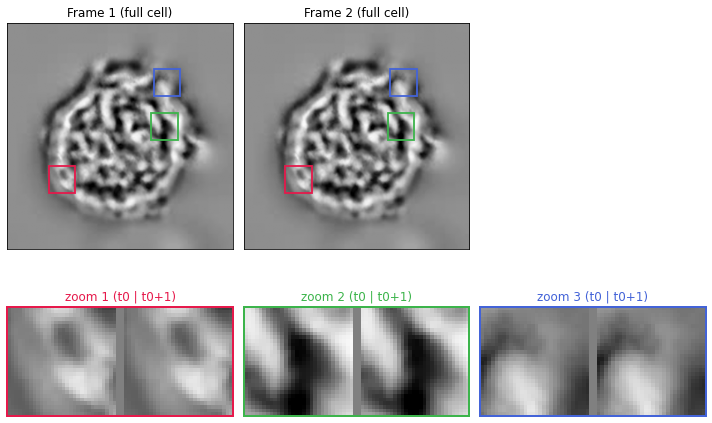

In [4]:
plot_pair_and_zooms(img1, img2, zoom_regions, ZOOM_COLORS, ZOOM)

## 3. Dense motion map with CompFlow-Patch (from the GitHub repo)

`dataset="SynthCells"` pulls the exact SynthCells-calibrated parameters the paper uses for this method (`CompFlow/configs/dataset_params.json`) -- no parameters to set by hand.

In [5]:
torch.manual_seed(0)
u_gh, v_gh = estimate_flow(img1, img2, method="CompFlow-Patch", dataset="SynthCells", device=DEVICE)

print(f"u: shape={u_gh.shape}  mean={u_gh.mean():.4f}")
print(f"v: shape={v_gh.shape}  mean={v_gh.mean():.4f}")
print(f"|w| mean (inside mask) = {np.hypot(u_gh, v_gh)[mask > 0].mean():.4f} px/frame")

u: shape=(256, 256)  mean=-0.0024
v: shape=(256, 256)  mean=-0.0032
|w| mean (inside mask) = 0.0851 px/frame


## 4. Plotting the dense motion map

Same visual convention as `Results/figura_potencial_metodo/` throughout the paper: **full cell = a fully dense per-pixel direction map** (every pixel gets a color, no arrows -- arrows that dense would just be a solid block); **zoom = actual colored quiver arrows** (hue = direction, same HSV colormap as the dense map, thickness tiered by magnitude, staggered grid so the spacing looks even). SynthCells ships dense per-pixel ground truth, so the direction and magnitude columns are each shown **twice, side by side: `CompFlow-Patch` (estimated) vs. ground truth** -- 7 columns in total, the same first 5 of `figura_potencial_metodo_celula1_K3_p123_salto40.png` plus the GT pair.

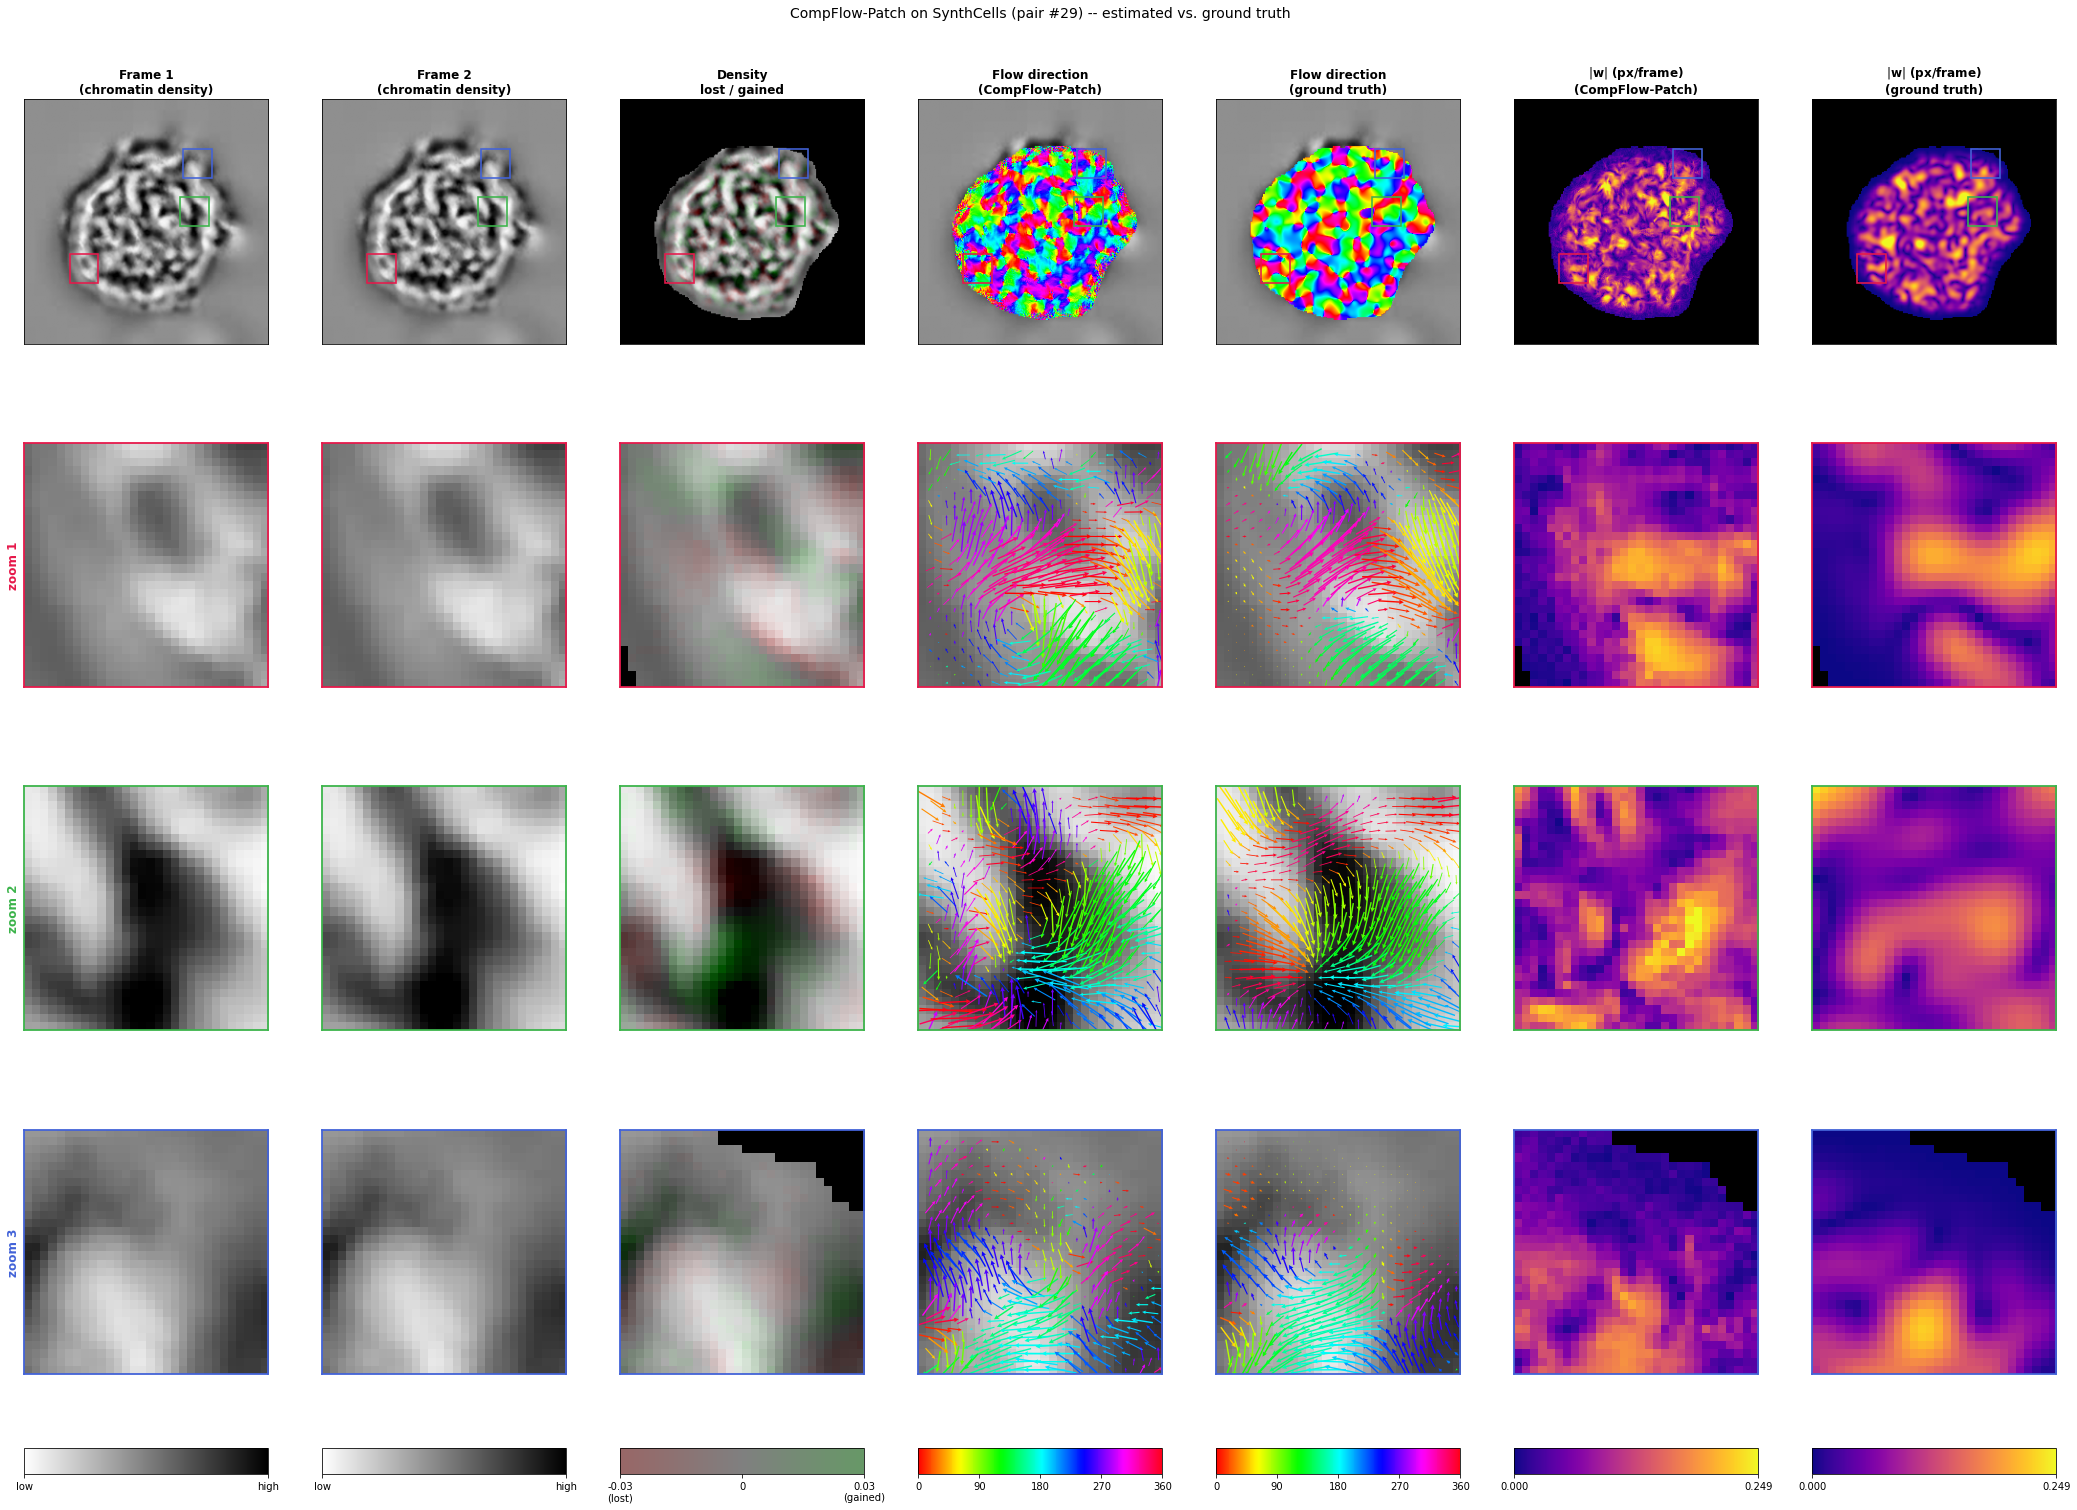

In [6]:
plot_motion_map_with_gt(
    img1, img2, mask, u_gh, v_gh, gt["u_gt"], gt["v_gt"],
    zoom_regions, ZOOM_COLORS, ZOOM,
    suptitle=f"CompFlow-Patch on SynthCells (pair #{PAIR_IDX}) -- estimated vs. ground truth",
)

## 5. Cross-check against `paper 1/main` -- does it give the same result?

Same frame pair, same method (`CompFlow-Patch` = `DF_WEDC_LK`), same SynthCells-calibrated parameters, same random seed -- but now using the **original** implementation the paper's `main.py` actually runs (`paper 1/Methods/density_flow_wedc_ventana.py`), not the GitHub copy.

One wrinkle: both the GitHub repo and `paper 1/Methods/` ship their own file named `common.py` (same purpose -- density construction -- different parameter-name convention, English vs. Spanish). Python only keeps one module named `common` cached at a time, and the GitHub one is already loaded from the cells above, so we drop it from the cache and put `paper 1/Methods` first on `sys.path` before importing the original module -- this only affects what `density_flow_wedc_ventana` (imported fresh right after) picks up; `compflow_patch` from the GitHub repo already finished importing earlier and is unaffected.

In [7]:
_PAPER1 = os.path.dirname(os.getcwd())  # .../paper 1
del sys.modules["common"]               # drop the GitHub repo's cached common.py
sys.path.insert(0, os.path.join(_PAPER1, "Methods"))
sys.path.insert(0, os.path.join(_PAPER1, "main", "datasets"))

import density_flow_wedc_ventana as main_compflow_patch   # the ORIGINAL implementation
import synth_cells                                         # the ORIGINAL (Spanish-keyed) calibrated params

params_main = dict(synth_cells.PARAMS["DF_WEDC_LK"])
print("paper 1/main parameters:", params_main)

torch.manual_seed(0)
state_main = main_compflow_patch.prepare(params_main, device=DEVICE)
u_main, v_main, _ = main_compflow_patch.run(state_main, params_main, img1, img2, device=DEVICE)

paper 1/main parameters: {'desenfoque': 1, 'flujo_cromatina': True, 'iteraciones': 100, 'tasa_aprendizaje': 0.05, 'window_size': 5}


GitHub   |w| mean (mask) = 0.085075
main     |w| mean (mask) = 0.085075
max|du| = 9.79e-04   max|dv| = 7.89e-04  (floating-point/CUDA noise floor, not a real difference)


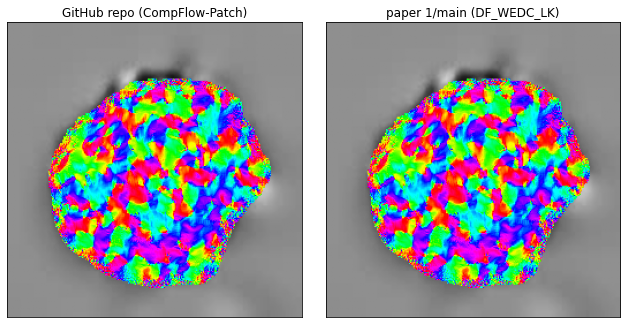

In [8]:
max_du = np.abs(u_gh - u_main).max()
max_dv = np.abs(v_gh - v_main).max()
print(f"GitHub   |w| mean (mask) = {np.hypot(u_gh, v_gh)[mask > 0].mean():.6f}")
print(f"main     |w| mean (mask) = {np.hypot(u_main, v_main)[mask > 0].mean():.6f}")
print(f"max|du| = {max_du:.2e}   max|dv| = {max_dv:.2e}  (floating-point/CUDA noise floor, not a real difference)")

plot_dense_direction_comparison(img1, mask, u_gh, v_gh, u_main, v_main,
                                "GitHub repo (CompFlow-Patch)", "paper 1/main (DF_WEDC_LK)")

Both panels should look identical, and `max|du|`/`max|dv|` should be tiny (`~1e-3` or smaller on values of order `1`) -- confirming the GitHub repo reproduces the original implementation exactly, modulo ordinary floating-point noise.